# Finding the root-cause alarm in an alarm flood
### Causal discovery on Huawei telecom alarm logs (gCastle)

**The operational problem.** A single network fault, such as a power outage or a failed microwave link, triggers dozens of alarms across many devices at once. Operators in a network operations center (NOC) have to guess which alarm is the cause and which ones are only consequences. If the cause-and-effect relations between alarm types are known, one root alarm can replace dozens of tickets.

**The question.** Can those relations be learned directly from the alarm log, and how close do they get to a graph drawn by experts?

**Contents**
1. Data and answer key
2. How to measure a causal graph, in operational terms
3. Three methods: simple time association (lift), PC and TTPM
4. Comparison, topology ablation and sensitivity
5. From graph to action: alarm triage
6. Conclusions and limitations

All numbers are recomputed in this notebook. The full experiments, including the sensitivity sweeps, are in `scripts/run_experiments.py`; their output is in `results/`.

In [1]:
import io, contextlib, logging, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
logging.disable(logging.CRITICAL)          # gCastle logs every TTPM iteration at INFO level
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from alarmrca import viz
from alarmrca.data import DATASETS, list_datasets, load_dataset
from alarmrca.metrics import edge_status, graph_metrics, random_reference
from alarmrca.baseline import lagged_cooccurrence, select_edges
from alarmrca.pc_method import run_pc
from alarmrca.rca import explain_alarms, root_ranking, topo_rank
with contextlib.redirect_stdout(io.StringIO()):          # gCastle prints a message on import
    from alarmrca.ttpm_fast import fit_ttpm

viz.style()
RES = ROOT / "results"
saved = pd.read_csv(RES / "metrics.csv")
sens = pd.read_csv(RES / "sensitivity.csv")
tri = pd.read_csv(RES / "triage.csv")
SHORT = {k: v["short"] for k, v in DATASETS.items()}
datasets = {n: load_dataset(n) for n in list_datasets()}
HOPS = {n: (0 if d.topology is None else 2) for n, d in datasets.items()}   # topology hops used per dataset

## 1. Data and answer key

Three real alarm logs were released by Huawei Noah's Ark Lab through [gCastle](https://github.com/huawei-noah/trustworthyAI/tree/master/gcastle) (Apache-2.0). Each dataset contains:

- `Alarm.csv`: one row per alarm (`alarm_id`, `device_id`, `start_timestamp`, `end_timestamp`, in seconds).
- `DAG.npy`: the **answer key**, a cause-and-effect graph between alarm *types* annotated by experts. `DAG[i, j] = 1` means alarm type *i* causes alarm type *j*.
- `Topology.npy`: the adjacency matrix between devices (Microwave datasets only).

Alarm type and device names are anonymized, so relations can only be read from timing patterns.

In [2]:
rows = []
for n, d in datasets.items():
    k = d.n_types
    rows.append({"dataset": SHORT[n], "alarms": d.n_events, "alarm types": k, "devices": d.n_devices,
                 "days": round(d.span_days, 1), "expert edges": int(d.true_dag.sum()),
                 "expert graph density": round(d.true_dag.sum() / (k * (k - 1)), 3),
                 "topology links": 0 if d.topology is None else int(d.topology.sum() // 2)})
pd.DataFrame(rows).set_index("dataset")

,alarms,alarm types,devices,days,expert edges,expert graph density,topology links
dataset,,,,,,,
Wireless,34838,18,55,240.1,69,0.225,0
Microwave-24,64598,24,439,6.0,137,0.248,395
Microwave-25,48572,25,474,6.0,148,0.247,440


In [3]:
datasets["24V_439N_Microwave"].alarms.head(8)

,alarm_id,device_id,start,end
0,11,55,0,0
1,12,260,23,23
2,3,107,32,32
3,5,107,32,32
4,10,107,32,32
5,4,107,34,34
6,3,377,36,36
7,3,70,67,67


Two facts will keep coming back below:

1. **The expert graphs are dense**: about 22 to 25 percent of all pairs of alarm types are related. Guessing edges at random already gives an F1 of about 0.23.
2. **Timestamps have one-second resolution**: many related alarms are recorded in the same second, so event order alone cannot settle the direction of cause and effect.

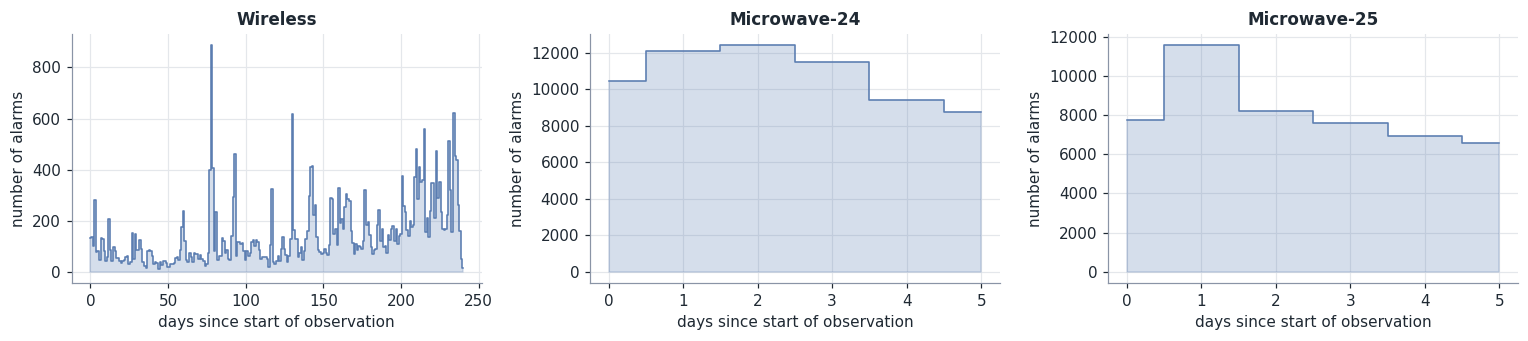

,alarms in the same second as the previous alarm,zero-duration alarms,most frequent type
dataset,,,
Wireless,2%,3%,A5 (21%)
Microwave-24,24%,100%,A0 (19%)
Microwave-25,29%,100%,A0 (12%)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, (n, d) in zip(axes, datasets.items()):
    viz.plot_alarm_rate(ax, d.alarms, unit="day")
    ax.set_title(SHORT[n])
fig.tight_layout()
plt.show()

stats = []
for n, d in datasets.items():
    a = d.alarms
    stats.append({"dataset": SHORT[n],
                  "alarms in the same second as the previous alarm": f"{(a['start'].diff() == 0).mean():.0%}",
                  "zero-duration alarms": f"{((a['end'] - a['start']) == 0).mean():.0%}",
                  "most frequent type": f"A{a['alarm_id'].value_counts().index[0]} ({a['alarm_id'].value_counts().iloc[0] / len(a):.0%})"})
pd.DataFrame(stats).set_index("dataset")

**How long is the gap from cause to effect?** For every alarm that has a parent in the expert graph, take the nearest parent alarm (same device or a neighbor, up to one hour earlier). The distribution of gaps shows the time scale a model has to capture. This is exploration only; the expert graph is not used to tune any method.

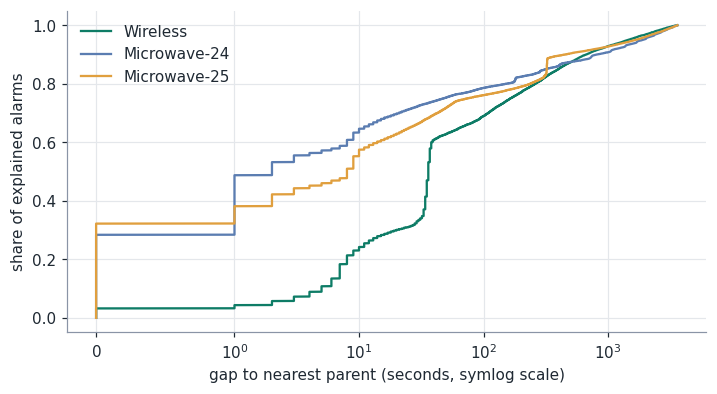

,explained alarms (1 hour),median gap (seconds),90th percentile (seconds)
dataset,,,
Wireless,32%,36,665
Microwave-24,59%,2,812
Microwave-25,60%,8,451


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = [viz.PALETTE["TTPM"], viz.PALETTE["PC"], viz.PALETTE["Lift"]]
lag_rows = []
for c, (n, d) in zip(colors, datasets.items()):
    ex = explain_alarms(d.alarms, d.true_dag, d.topology, d.n_devices, window=3600, hops=HOPS[n])
    lag = np.sort(ex.loc[~ex["is_root"], "lag"].to_numpy())
    ax.plot(lag, np.arange(1, len(lag) + 1) / len(lag), color=c, label=SHORT[n])
    lag_rows.append({"dataset": SHORT[n], "explained alarms (1 hour)": f"{len(lag) / len(ex):.0%}",
                     "median gap (seconds)": int(np.median(lag)), "90th percentile (seconds)": int(np.percentile(lag, 90))})
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("gap to nearest parent (seconds, symlog scale)")
ax.set_ylabel("share of explained alarms")
ax.legend(frameon=False)
plt.show()
pd.DataFrame(lag_rows).set_index("dataset")

## 2. How to measure a causal graph

The learned graph is compared edge by edge with the expert graph. In operational terms:

| Metric | Meaning |
|---|---|
| **Precision** | Out of every 10 relations the model reports, how many are in the expert graph. Low precision floods operators with false "causes". |
| **Recall** | Out of all relations in the expert graph, how many were found. Low recall hides many fault-propagation paths. |
| **F1** | Harmonic mean of precision and recall, computed strictly on directed edges (the `MetricsDAG` convention of gCastle, so it is comparable with Huawei's table). |
| **SHD** | Number of corrections (add an edge, remove an edge, reverse an edge) still needed. Lower is better. |

A small example with three alarm types:

In [6]:
truth = np.array([[0, 1, 1], [0, 0, 1], [0, 0, 0]])     # A0 -> A1, A0 -> A2, A1 -> A2
est   = np.array([[0, 1, 0], [0, 0, 0], [1, 1, 0]])     # A0 -> A1 (correct), A2 -> A0 and A2 -> A1 (reversed)
print({k: v for k, v in graph_metrics(est, truth).items() if k in ("tp", "fp", "fn", "reversed", "precision", "recall", "f1", "shd")})
print(edge_status(est, truth))

{'tp': 1, 'fp': 2, 'fn': 2, 'reversed': 2, 'precision': 0.3333, 'recall': 0.3333, 'f1': 0.3333, 'shd': 2}
{(0, 1): 'correct', (2, 0): 'reversed', (2, 1): 'reversed'}


**Chance level.** Because the expert graphs are dense, the F1 of a random guess is far from zero. The fair comparison is a random DAG with as many edges as the method returned (column `f1_chance` in `results/metrics.csv`).

In [7]:
ref = pd.DataFrame({SHORT[n]: random_reference(d.true_dag, n_draws=200) for n, d in datasets.items()}).T
ref[["precision", "recall", "f1"]].round(3)

,precision,recall,f1
Wireless,0.227,0.227,0.227
Microwave-24,0.242,0.242,0.242
Microwave-25,0.246,0.246,0.246


## 3. Three methods

All methods use library defaults or common practice and are **not tuned with the answer key**. Sensitivity sweeps are in section 4.

### 3.1 Simple baseline: temporal association (lift)

For every pair of alarm types (a, b), compute the share of b alarms preceded by an a alarm within 60 seconds (on the same device, or on neighbors up to 2 hops away when a topology exists). Divide by the chance level if a alarms arrived at random at their historical rate. Pairs with lift of at least 3, confidence of at least 0.05 and support of at least 20 events become edges. Because alarms are rare, lift easily reaches the thousands; the thresholds that actually filter are confidence and support.

In [8]:
name = "18V_55N_Wireless"; ds = datasets[name]
t0 = time.time()
scores = lagged_cooccurrence(ds.alarms, ds.n_types, ds.topology, ds.n_devices, window=60, hops=HOPS[name])
g_lift = select_edges(scores, min_lift=3.0, min_conf=0.05, min_support=20)
print(f"time: {time.time() - t0:.1f} seconds")

pairs = pd.DataFrame([{"cause": f"A{a}", "effect": f"A{b}", "lift": scores["lift"][a, b],
                       "confidence": scores["confidence"][a, b], "support": scores["support"][a, b],
                       "in expert graph": bool(ds.true_dag[a, b])}
                      for a in range(ds.n_types) for b in range(ds.n_types) if a != b])
display(pairs[pairs["support"] >= 20].sort_values("lift", ascending=False).head(8).round(2).reset_index(drop=True))
print(graph_metrics(g_lift, ds.true_dag))

time: 1.3 seconds


,cause,effect,lift,confidence,support,in expert graph
0,A1,A10,3527.20,0.25,124,False
1,A8,A6,2990.70,0.06,255,True
2,A7,A14,2764.70,0.16,398,True
3,A8,A11,2363.22,0.06,304,True
4,A7,A6,1738.43,0.29,1293,True
5,A7,A11,1633.22,0.51,2547,True
6,A14,A11,1613.78,0.21,1060,False
7,A1,A14,1494.36,0.09,220,True


{'edges_pred': 24, 'edges_true': 69, 'tp': 17, 'fp': 7, 'fn': 52, 'reversed': 3, 'precision': 0.7083, 'recall': 0.2464, 'f1': 0.3656, 'skeleton_f1': 0.4301, 'shd': 56}


This baseline is fairly precise on Wireless but finds only a small share of the edges: it only looks at pairs, cannot tell a direct cause from an indirect one, and cannot decide the direction when two alarms are recorded in the same second.

### 3.2 PC (gCastle)

PC is a classic constraint-based algorithm built on conditional-independence tests. It needs a table, not a sequence of events, so the log becomes a 0/1 table: **one row = one device in one 10-minute window** (only rows that contain an alarm), **one column = one alarm type**. As a result PC sees neither the order of events inside a window nor the topology.

Technical note: gCastle's Fisher-z test recomputes the correlation on the full data for every test, which is slow. `alarmrca.pc_method.cached_fisherz` computes the correlation matrix once and yields exactly the same graph (tested in `tests/`).

In [9]:
t0 = time.time()
g_pc, info = run_pc(ds.alarms, ds.n_types, window=600, per_device=True, alpha=0.05)
print(f"time: {time.time() - t0:.1f} seconds | samples: {info['n_samples']} | variables: {info['n_vars']}")
print(graph_metrics(g_pc, ds.true_dag))

time: 2.2 seconds | samples: 18518 | variables: 18
{'edges_pred': 73, 'edges_true': 69, 'tp': 18, 'fp': 55, 'fn': 51, 'reversed': 20, 'precision': 0.2466, 'recall': 0.2609, 'f1': 0.2535, 'skeleton_f1': 0.5352, 'shd': 86}


### 3.3 TTPM (gCastle): topological Hawkes process

TTPM models the alarm log as a point process. The rate of alarms of type *i* on device *n* is raised by earlier alarms on that device and on its neighbors:

$$\lambda_i^{(n)}(t) \;=\; \mu_i \;+\; \sum_{j \in \mathrm{pa}(i)} \sum_{h=0}^{H} \alpha_{ji}^{(h)} \sum_{m \in \mathcal{N}_h(n)} \;\sum_{t_k^{(j,m)} < t} e^{-\delta\,(t - t_k^{(j,m)})}$$

*μ* is the base rate, *α* the strength of influence from type *j* on a device *h* hops away, and *δ* how fast the influence decays (gCastle default: 0.1 per second). Type *j* becomes a parent of type *i* when a graph containing the edge *j → i* improves the **BIC** score (log-likelihood minus a penalty on the number of parameters). The graph is searched by hill climbing: each iteration applies the single best edge change, and parameters are fitted with EM.

**Optimization added here.** gCastle's hill climbing calls `_em` for every candidate edge, and each call recomputes the likelihood of *all* alarm types. But changing one edge *j → i* only changes the likelihood term of type *i*. `FastTTPM` caches the score of each (child, parent set), so every candidate needs at most one new EM run. The formulas and the search order do not change. The check below shows an identical graph in much less time.

In [10]:
with contextlib.redirect_stdout(io.StringIO()):
    from alarmrca.ttpm_fast import FastTTPM
    from alarmrca.compat import load_castle
    _, StockTTPM, _ = load_castle()

d = datasets["18V_55N_Wireless"]; al = d.alarms.iloc[:1500]
X = pd.DataFrame({"event": al.alarm_id, "timestamp": al.start.astype(float), "node": al.device_id})
topo = np.zeros((d.n_devices, d.n_devices))
res = {}
for label, cls in (("stock gCastle TTPM", StockTTPM), ("FastTTPM (per-type cache)", FastTTPM)):
    t0 = time.time(); m = cls(topo, max_hop=0, max_iter=8); m.learn(X.copy()); res[label] = (time.time() - t0, np.asarray(m.causal_matrix))
(t_a, g_a), (t_b, g_b) = res.values()
print(f"identical graph: {np.array_equal(g_a, g_b)}")
print(f"stock: {t_a:.1f} s | cached: {t_b:.2f} s | {t_a / t_b:.0f}x faster (1,500 alarms, 8 iterations; the gap grows on the full data)")

identical graph: True
stock: 7.6 s | cached: 0.34 s | 22x faster (1,500 alarms, 8 iterations; the gap grows on the full data)


Now every method runs on the three full datasets. TTPM uses `max_hop=0` (no topology) on Wireless and `max_hop=2` on the Microwave datasets, following the gCastle example.

In [11]:
live, live_rows = {}, []
def record(name, method, g, secs):
    live[(name, method)] = g
    m = graph_metrics(g, datasets[name].true_dag)
    live_rows.append({"dataset": name, "method": method, "edges": m["edges_pred"], "correct": m["tp"], "reversed": m["reversed"],
                      "precision": m["precision"], "recall": m["recall"], "F1": m["f1"], "SHD": m["shd"], "seconds": round(secs, 1)})

for name, d in datasets.items():
    h = HOPS[name]
    t0 = time.time()
    sc = lagged_cooccurrence(d.alarms, d.n_types, d.topology, d.n_devices, window=60, hops=h)
    record(name, "Lift", select_edges(sc, 3.0, 0.05, 20), time.time() - t0)
    t0 = time.time(); g, _ = run_pc(d.alarms, d.n_types, window=600, per_device=True, alpha=0.05); record(name, "PC", g, time.time() - t0)
    r = fit_ttpm(d.alarms, d.topology, d.n_types, delta=0.1, max_hop=h); record(name, "TTPM", r.graph, r.runtime_s)

table = pd.DataFrame(live_rows)
table["dataset"] = table["dataset"].map(SHORT)
table

,dataset,method,edges,correct,reversed,precision,recall,F1,SHD,seconds
0,Wireless,Lift,24,17,3,0.7083,0.2464,0.3656,56,1.4
1,Wireless,PC,73,18,20,0.2466,0.2609,0.2535,86,2.3
2,Wireless,TTPM,51,37,9,0.7255,0.5362,0.6167,37,4.9
3,Microwave-24,Lift,68,18,24,0.2647,0.1314,0.1756,145,4.5
4,Microwave-24,PC,74,19,22,0.2568,0.1387,0.1801,150,1.1
5,Microwave-24,TTPM,83,42,16,0.5060,0.3066,0.3818,120,34.0
6,Microwave-25,Lift,151,31,44,0.2053,0.2095,0.2074,193,4.4
7,Microwave-25,PC,79,27,28,0.3418,0.1824,0.2379,145,1.0
8,Microwave-25,TTPM,82,35,23,0.4268,0.2365,0.3043,137,26.0


**Reproducibility check:** the numbers above must equal the saved results in `results/metrics.csv`.

In [12]:
max_diff = 0.0
for r in live_rows:
    s = saved[(saved["dataset"] == r["dataset"]) & (saved["method"] == r["method"]) & (saved["role"] == "main")].iloc[0]
    max_diff = max(max_diff, abs(s["f1"] - r["F1"]), abs(s["precision"] - r["precision"]))
print(f"largest F1/precision difference from results/metrics.csv: {max_diff:.6f}")
assert max_diff < 1e-6

largest F1/precision difference from results/metrics.csv: 0.000000


## 4. Comparison

### 4.1 F1 scores and chance level

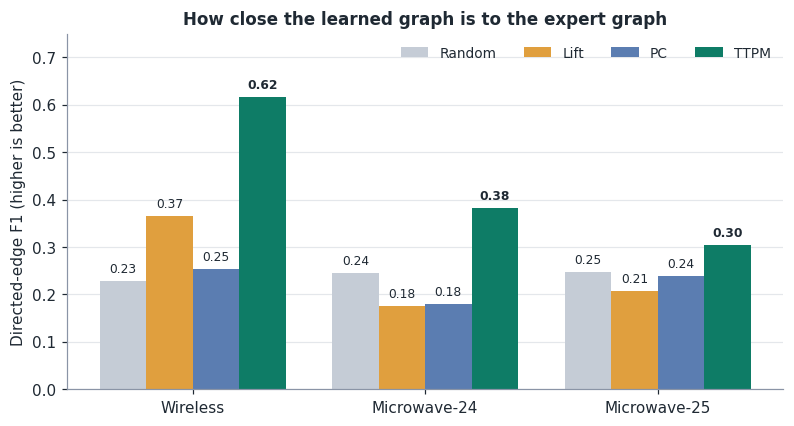

edges      f1  chance F1  F1 / chance
dataset      method                                       
Wireless     Lift     24.0  0.3656     0.1236         2.96
             PC       73.0  0.2535     0.2348         1.08
             TTPM     51.0  0.6167     0.2010         3.07
Microwave-24 Lift     68.0  0.1756     0.1637         1.07
             PC       74.0  0.1801     0.1746         1.03
             TTPM     83.0  0.3818     0.1930         1.98
Microwave-25 Lift    151.0  0.2074     0.2479         0.84
             PC       79.0  0.2379     0.1727         1.38
             TTPM     82.0  0.3043     0.1763         1.73

In [13]:
fig, ax = plt.subplots(figsize=(8.4, 4.2))
viz.plot_f1_bars(ax, saved, {k: SHORT[k] for k in SHORT})
ax.set_title("How close the learned graph is to the expert graph")
plt.show()

cmp = saved[saved["role"] == "main"][["dataset", "method", "edges_pred", "f1", "f1_chance"]].copy()
cmp["dataset"] = cmp["dataset"].map(SHORT)
cmp["F1 / chance"] = (cmp["f1"] / cmp["f1_chance"]).round(2)
cmp[cmp["method"] != "Random"].rename(columns={"edges_pred": "edges", "f1_chance": "chance F1"}).set_index(["dataset", "method"])

### 4.2 Where are the mistakes?

Each cell is one pair (cause in the row, effect in the column). Green: correct. Red: an edge that is not in the expert graph. Yellow: the relation exists but the direction is reversed. Gray: an expert edge that was missed.

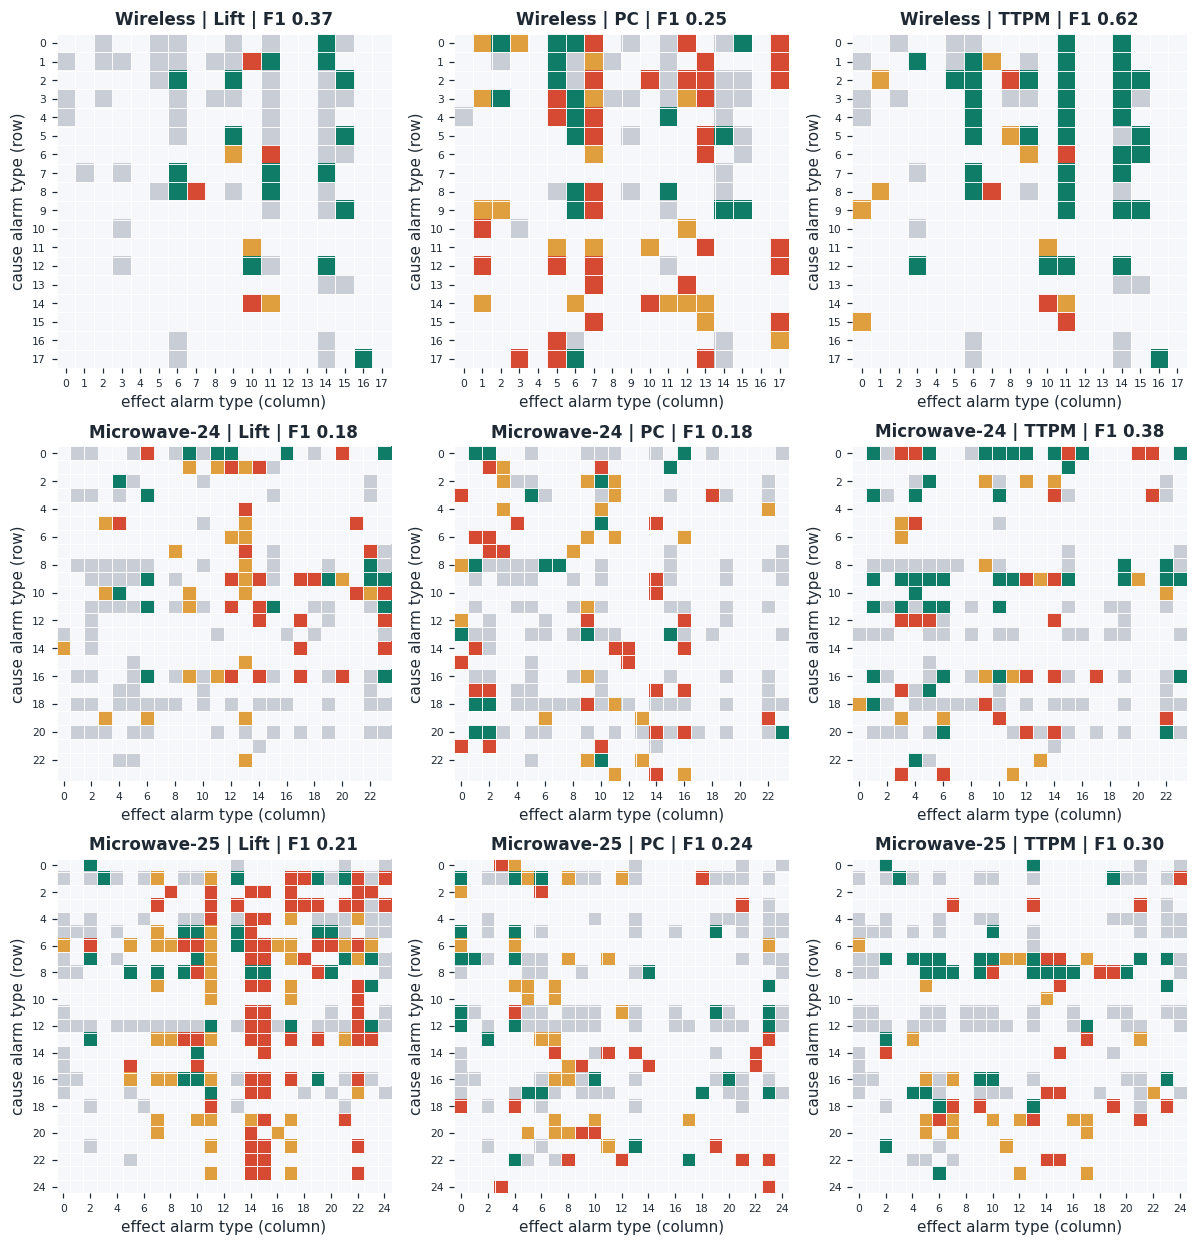

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11.4))
for r_, (name, d) in enumerate(datasets.items()):
    for c_, method in enumerate(("Lift", "PC", "TTPM")):
        g = live[(name, method)]
        viz.plot_edge_matrix(axes[r_, c_], g, d.true_dag, f"{SHORT[name]} | {method} | F1 {graph_metrics(g, d.true_dag)['f1']:.2f}")
fig.tight_layout()
plt.show()

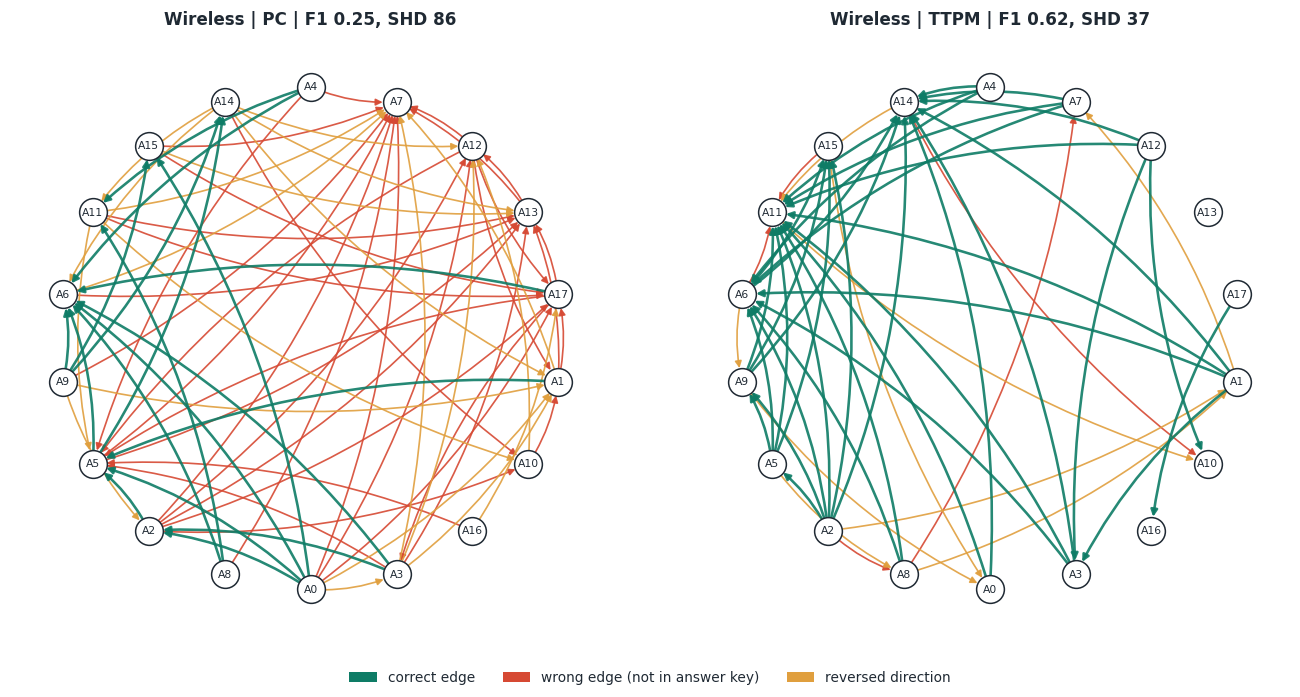

In [15]:
d = datasets["18V_55N_Wireless"]; pos = viz.circular_positions(d.true_dag)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.2))
for ax, method in zip(axes, ("PC", "TTPM")):
    g = live[("18V_55N_Wireless", method)]; m = graph_metrics(g, d.true_dag)
    viz.plot_graph(ax, g, d.true_dag, pos, f"Wireless | {method} | F1 {m['f1']:.2f}, SHD {m['shd']}", show_missed=False)
    ax.set_aspect("equal")
fig.tight_layout(rect=(0, 0.05, 1, 1))
viz.graph_legend(fig, loc="lower center", ncol=3, statuses=("correct", "wrong", "reversed"))
plt.show()

### 4.3 Does topology help TTPM?

`max_hop=0` makes TTPM treat every device separately. `max_hop=1` and `2` let alarms on neighboring devices influence each other.

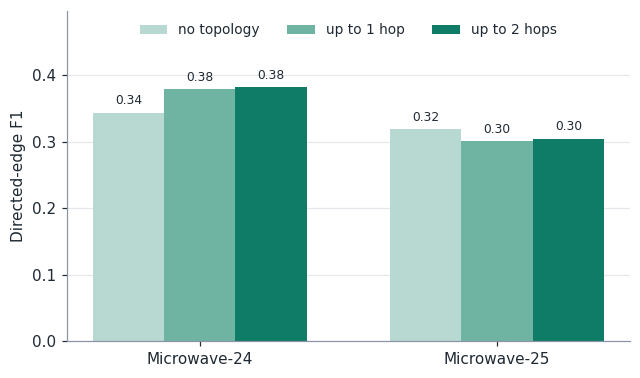

In [16]:
fig, ax = plt.subplots(figsize=(6.6, 3.9))
viz.plot_topology_ablation(ax, saved, SHORT)
plt.show()

### 4.4 How sensitive are the results?

TTPM is swept over the decay parameter *δ* (a 100-fold range). PC is swept over the window type, window width and significance level; the lift baseline over window width and thresholds. **The best configuration in each sweep is picked using the answer key, so it is over-optimistic for PC and lift**; treat it as an upper bound, not a fair result.

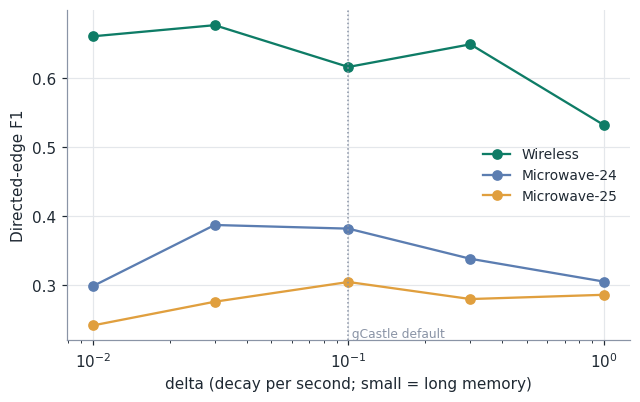

lowest F1 in sweep  highest F1 in sweep
dataset      method                                         
Wireless     TTPM                 0.532                0.677
             PC                   0.254                0.376
             Lift                 0.226                0.404
Microwave-24 TTPM                 0.298                0.387
             PC                   0.038                0.240
             Lift                 0.000                0.176
Microwave-25 TTPM                 0.241                0.304
             PC                   0.071                0.238
             Lift                 0.000                0.207

In [17]:
fig, ax = plt.subplots(figsize=(6.6, 3.9))
viz.plot_delta_sensitivity(ax, sens, SHORT)
plt.show()

best = (sens.groupby(["dataset", "method"], sort=False)["f1"].agg(["min", "max"]).round(3)
        .rename(columns={"min": "lowest F1 in sweep", "max": "highest F1 in sweep"}))
best.index = best.index.set_levels([SHORT[x] for x in best.index.levels[0]], level=0, verify_integrity=False)
best

In [18]:
worst_ttpm = sens[sens["method"] == "TTPM"].groupby("dataset")["f1"].min()
best_other = sens[sens["method"].isin(["PC", "Lift"])].groupby("dataset")["f1"].max()
display(Markdown("**TTPM at its worst delta vs PC/lift at their best configuration (chosen with the answer key):**\n\n"
    + "\n".join(f"- {SHORT[n]}: TTPM {worst_ttpm[n]:.3f} vs {best_other[n]:.3f}" for n in worst_ttpm.index)))

**TTPM at its worst delta vs PC/lift at their best configuration (chosen with the answer key):**

- Wireless: TTPM 0.532 vs 0.404
- Microwave-24: TTPM 0.298 vs 0.240
- Microwave-25: TTPM 0.241 vs 0.238

## 5. From graph to action: alarm triage

A causal graph is useful if it can filter an alarm flood. The rule is simple: an alarm is **explained** when the graph gives its type a parent and an alarm of that parent type appeared within the previous 60 seconds on the same device or a neighbor (up to 2 hops). Unexplained alarms are **root alarms**. Each alarm points to its nearest parent, so every root alarm owns a tree of descendants, and roots are ranked by the number of alarms they explain.

An important warning: this dataset has **no cause label for individual events**, only a graph at the alarm-type level. So the percentage of explained alarms is not accuracy. The TTPM graph is learned from the same log, so it is natural that it explains many alarms. What can be checked is whether the result beats chance (a random DAG of the same size) and how well its root alarms agree with the root alarms under the expert graph.

In [19]:
t = tri.copy(); t["dataset"] = t["dataset"].map(SHORT)
t["explained_frac"] = (t["explained_frac"] * 100).round(1); t["explained_frac_random"] = (t["explained_frac_random"] * 100).round(1)
t = t.rename(columns={"explained_frac": "explained (%)", "explained_frac_random": "explained by random DAG of same size (%)",
                      "root_precision": "root precision vs expert", "root_recall": "root recall vs expert"})
t.drop(columns=["window_s", "hops"]).set_index(["dataset", "graph"])

edges  explained (%)  \
dataset      graph                          
Wireless     Expert     69           20.8   
             TTPM       51           23.7   
             PC         73            9.2   
             Lift       24           21.5   
Microwave-24 Expert    137           45.2   
             TTPM       83           49.0   
             PC         74           40.5   
             Lift       68           31.8   
Microwave-25 Expert    148           44.2   
             TTPM       82           50.7   
             PC         79           24.4   
             Lift      151           49.7   

                     explained by random DAG of same size (%)  \
dataset      graph                                              
Wireless     Expert                                       6.7   
             TTPM                                         4.2   
             PC                                           7.9   
             Lift                                         3.5   
Microwave-24 Expert                                      30.1   
             TTPM                                        19.7   
             PC                                          14.8   
             Lift                                        17.5   
Microwave-25 Expert                                      33.0   
             TTPM                                        18.3   
             PC                                          27.3   
             Lift                                        31.2   

                     root precision vs expert  root recall vs expert  
dataset      graph                                                    
Wireless     Expert                       NaN                    NaN  
             TTPM                      0.9860                 0.9498  
             PC                        0.8316                 0.9527  
             Lift                      0.9602                 0.9520  
Microwave-24 Expert                       NaN                    NaN  
             TTPM                      0.8507                 0.7922  
             PC                        0.7722                 0.8388  
             Lift                      0.6045                 0.7522  
Microwave-25 Expert                       NaN                    NaN  
             TTPM                      0.9153                 0.8074  
             PC                        0.5671                 0.7675  
             Lift                      0.8937                 0.8045

- **Busiest** burst: 485 alarms become 428 root alarms under the TTPM graph (12% explained), but only 235 under the expert graph (52% explained). The largest gap is alarm type A7: 191 A7 alarms are roots under TTPM but are explained by the expert graph (parents of A7 in the expert graph: A8, A18; in the TTPM graph: none). The data show why: 98% of A7 alarms are recorded on the same device and in the same second as one of its parents, while gCastle's TTPM only counts influence from alarms recorded in an earlier second.
- **Best-explained** burst among the 20 busiest: 229 alarms become 74 root alarms (68% explained). This is the best example, not the average.

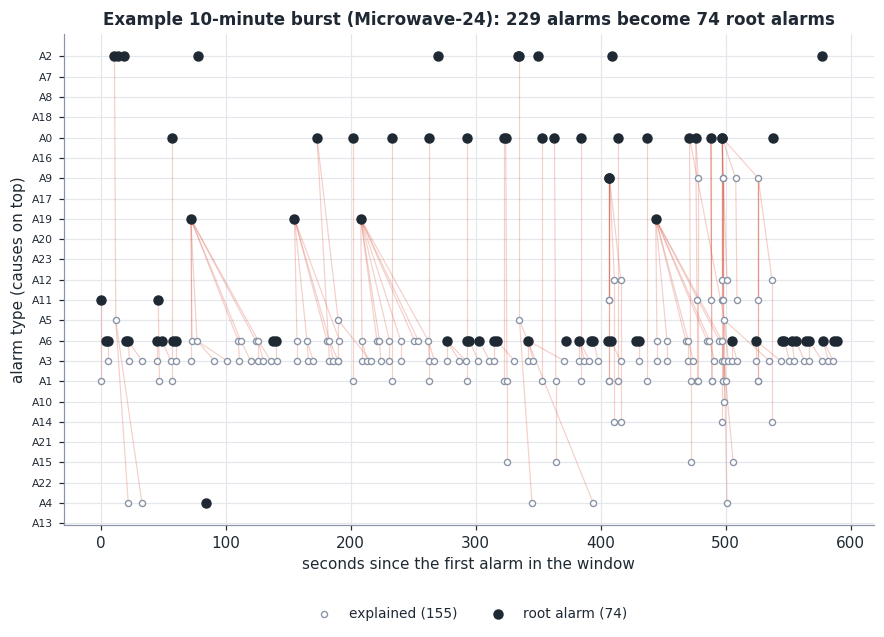

In [20]:
name = "24V_439N_Microwave"; d = datasets[name]; g_ttpm = live[(name, "TTPM")]
width, base = 600, int(d.alarms["start"].min())
counts = ((d.alarms["start"] - base) // width).value_counts()

def window(bin_id, graph):
    t0 = int(bin_id * width + base)
    sl = d.alarms[(d.alarms["start"] >= t0 - 60) & (d.alarms["start"] < t0 + width)]
    ex = explain_alarms(sl, graph, d.topology, d.n_devices, window=60, hops=2)
    return t0, ex[ex["start"] >= t0]

# busiest burst vs the burst (among the 20 busiest) that is best explained
busiest = window(counts.index[0], g_ttpm)[1]
busiest_exp = window(counts.index[0], d.true_dag)[1]
gap = (busiest.groupby("alarm_id")["is_root"].sum() - busiest_exp.groupby("alarm_id")["is_root"].sum()).sort_values(ascending=False)
gt = int(gap.index[0])                                   # alarm type with the largest root gap between TTPM and the expert graph
par_exp = ", ".join(f"A{p}" for p in np.flatnonzero(d.true_dag[:, gt])) or "none"
par_tt = ", ".join(f"A{p}" for p in np.flatnonzero(g_ttpm[:, gt])) or "none"
parent_events = d.alarms[d.alarms["alarm_id"].isin(np.flatnonzero(d.true_dag[:, gt]))][["device_id", "start"]].drop_duplicates()
child_events = d.alarms[d.alarms["alarm_id"] == gt]
same_second = len(child_events.merge(parent_events, on=["device_id", "start"])) / len(child_events)
cand = max(((len(e) - int(e["is_root"].sum()), b) for b in counts.index[:20] for e in [window(b, g_ttpm)[1]]))
t0, ex = window(cand[1], g_ttpm)
ex = ex[(ex["parent_row"] < 0) | ex["parent_row"].isin(ex.index)]   # drop alarms whose parent lies before the window
display(Markdown(f"- **Busiest** burst: {len(busiest)} alarms become {int(busiest['is_root'].sum())} root alarms under the TTPM graph "
                 f"({1 - busiest['is_root'].mean():.0%} explained), but only {int(busiest_exp['is_root'].sum())} under the expert graph "
                 f"({1 - busiest_exp['is_root'].mean():.0%} explained). The largest gap is alarm type A{gt}: {int(gap.iloc[0])} A{gt} alarms are roots under TTPM "
                 f"but are explained by the expert graph (parents of A{gt} in the expert graph: {par_exp}; in the TTPM graph: {par_tt}). "
                 f"The data show why: {same_second:.0%} of A{gt} alarms are recorded on the same device and in the same second as one of its parents, "
                 f"while gCastle's TTPM only counts influence from alarms recorded in an earlier second.\n"
                 f"- **Best-explained** burst among the 20 busiest: {len(ex)} alarms become {int(ex['is_root'].sum())} root alarms "
                 f"({1 - ex['is_root'].mean():.0%} explained). This is the best example, not the average."))

fig, ax = plt.subplots(figsize=(9.5, 5.8))
viz.plot_swimlane(ax, ex, topo_rank(g_ttpm), f"Example 10-minute burst (Microwave-24): {len(ex)} alarms become {int(ex['is_root'].sum())} root alarms")
plt.show()

In [21]:
rk = root_ranking(ex).head(8).copy()
rk["alarm_id"] = "A" + rk["alarm_id"].astype(str)
rk["start"] = (rk["start"] - t0).astype(int)
rk.rename(columns={"alarm_id": "type", "device_id": "device", "start": "seconds since window start", "n_explained": "alarms explained"}).reset_index(drop=True)

,type,device,seconds since window start,alarms explained
0,A0,90,506,17
1,A19,81,217,15
2,A19,81,81,14
3,A19,81,453,14
4,A19,81,164,10
5,A0,261,480,10
6,A9,90,416,8
7,A0,261,182,4


## 6. Conclusions and limitations

In [22]:
m = saved[saved["role"] == "main"].pivot(index="method", columns="dataset", values="f1")
names = [SHORT[c] for c in m.columns]
fmt = lambda s: ", ".join(f"{v:.2f}" for v in s)
def ratio(meth):
    r_ = saved[(saved["role"] == "main") & (saved["method"] == meth)].set_index("dataset")
    return r_["f1"] / r_["f1_chance"]
gain, pc_r, lift_r = ratio("TTPM"), ratio("PC"), ratio("Lift")
fmt1 = lambda s: " / ".join(f"{v:.1f}" for v in s)
display(Markdown(f'''
**Findings** (dataset order: {", ".join(names)})

1. **TTPM is closest to the expert graph on all three datasets**: F1 {fmt(m.loc["TTPM"])}, against PC {fmt(m.loc["PC"])} and the lift baseline {fmt(m.loc["Lift"])}. That is {gain.min():.1f} to {gain.max():.1f} times the chance level.
2. **Relative to chance level (the F1 of a random DAG of the same size)**, PC reaches {fmt1(pc_r)} times, the lift baseline {fmt1(lift_r)} times and TTPM {fmt1(gain)} times. PC only sees a table of occurrences; TTPM uses event order and decaying influence. On the Microwave datasets every method is still far from the expert graph (TTPM recall is only 0.24 to 0.31).
3. **Topology helps inconsistently.** On Microwave-24, TTPM's F1 rises from {saved[(saved.dataset=="24V_439N_Microwave") & (saved.method=="TTPM hop<=0")]["f1"].iloc[0]:.2f} (no topology) to {saved[(saved.dataset=="24V_439N_Microwave") & (saved.method=="TTPM")]["f1"].iloc[0]:.2f}; on Microwave-25 the change is not positive ({saved[(saved.dataset=="25V_474N_Microwave") & (saved.method=="TTPM hop<=0")]["f1"].iloc[0]:.2f} to {saved[(saved.dataset=="25V_474N_Microwave") & (saved.method=="TTPM")]["f1"].iloc[0]:.2f}). Two datasets are too few to conclude.
4. **TTPM is stable with respect to delta** over a 100-fold range, and even its worst setting matches or beats the best PC/lift configuration.
'''))


**Findings** (dataset order: Wireless, Microwave-24, Microwave-25)

1. **TTPM is closest to the expert graph on all three datasets**: F1 0.62, 0.38, 0.30, against PC 0.25, 0.18, 0.24 and the lift baseline 0.37, 0.18, 0.21. That is 1.7 to 3.1 times the chance level.
2. **Relative to chance level (the F1 of a random DAG of the same size)**, PC reaches 1.1 / 1.0 / 1.4 times, the lift baseline 3.0 / 1.1 / 0.8 times and TTPM 3.1 / 2.0 / 1.7 times. PC only sees a table of occurrences; TTPM uses event order and decaying influence. On the Microwave datasets every method is still far from the expert graph (TTPM recall is only 0.24 to 0.31).
3. **Topology helps inconsistently.** On Microwave-24, TTPM's F1 rises from 0.34 (no topology) to 0.38; on Microwave-25 the change is not positive (0.32 to 0.30). Two datasets are too few to conclude.
4. **TTPM is stable with respect to delta** over a 100-fold range, and even its worst setting matches or beats the best PC/lift configuration.


**Limitations**

- **The answer key is an expert annotation at the alarm-type level.** It may be incomplete, so precision can look lower than it really is. The dataset also has no per-event cause labels, so triage accuracy cannot be measured; section 5 only demonstrates how to use a graph.
- **TTPM (the gCastle implementation) does not see relations recorded in the same second**, because only alarms with an earlier timestamp are counted as influences. On the Microwave datasets 24 to 29 percent of alarms are in the same second as the previous alarm (section 1), and a concrete case is A8 → A7 in section 5. This probably contributes to the low recall there.
- **Only three datasets, one data realization each.** Small differences between methods (for example the effect of topology) should not be read as definite. There are no repeated runs with different random seeds because the methods used are deterministic.
- **The main configuration is not tuned**, while the best PC and lift configurations in the sweeps are chosen with the answer key. The comparison deliberately favors TTPM's competitors.
- **Huawei's reference scores** for the same datasets (the `datasets` README of gCastle) use a protocol that is not fully known. They are context only, not an apples-to-apples comparison.
- **The data come from networks of unknown origin** supplied by Huawei; results may not transfer to other networks.

**Reasonable next steps**

- Try other gCastle algorithms that accept event data, or the THP variant from its paper.
- Rewrite the Hawkes likelihood in MindSpore (Huawei's AI framework) so edges are learned with gradients and an L1 penalty instead of hill climbing.
- Ask domain experts to validate a few alarm bursts to judge triage quality at the event level.